准备优化 15 种组合 (m=0~2, n=1~5)
【物理设定】：OPA增益 g 在 [1.03, 1.5] 内高精度寻优，目标态 r_ideal < 0，gamma > 0，请耐心等待...
完成! F=0.9607 | g=1.462 
完成! F=0.9853 | g=1.077 
完成! F=0.9929 | g=1.032 
完成! F=0.9870 | g=1.030 
完成! F=0.9811 | g=1.030 
完成! F=0.9953 | g=1.030 
完成! F=0.9607 | g=1.462 
完成! F=0.9841 | g=1.432 
完成! F=0.9410 | g=1.030 
完成! F=0.9928 | g=1.044 
完成! F=0.9941 | g=1.030 
完成! F=0.9946 | g=1.159 
完成! F=0.9607 | g=1.462 
完成! F=0.9607 | g=1.032 
完成! F=0.9792 | g=1.107 
完成! F=0.9824 | g=1.030 
完成! F=0.9713 | g=1.051 
完成! F=0.9939 | g=1.093 
完成! F=0.9607 | g=1.462 
完成! F=0.9513 | g=1.088 
完成! F=0.9238 | g=1.112 
完成! F=0.9431 | g=1.030 
完成! F=0.9739 | g=1.049 
完成! F=0.9903 | g=1.043 
完成! F=0.9607 | g=1.462 
完成! F=0.9462 | g=1.140 
完成! F=0.9666 | g=1.264 
完成! F=0.9738 | g=1.091 
完成! F=0.9821 | g=1.038 
完成! F=0.9578 | g=1.079 
完成! F=0.9577 | g=1.241 
完成! F=0.7984 | g=1.030 
完成! F=0.9608 | g=1.227 
完成! F=0.8551 | g=1.116 
完成! F=0.9663 | g=1.070 
完成! F=0.9782 | g=1.030 

m   | n   | Fidelity | g      | gamma

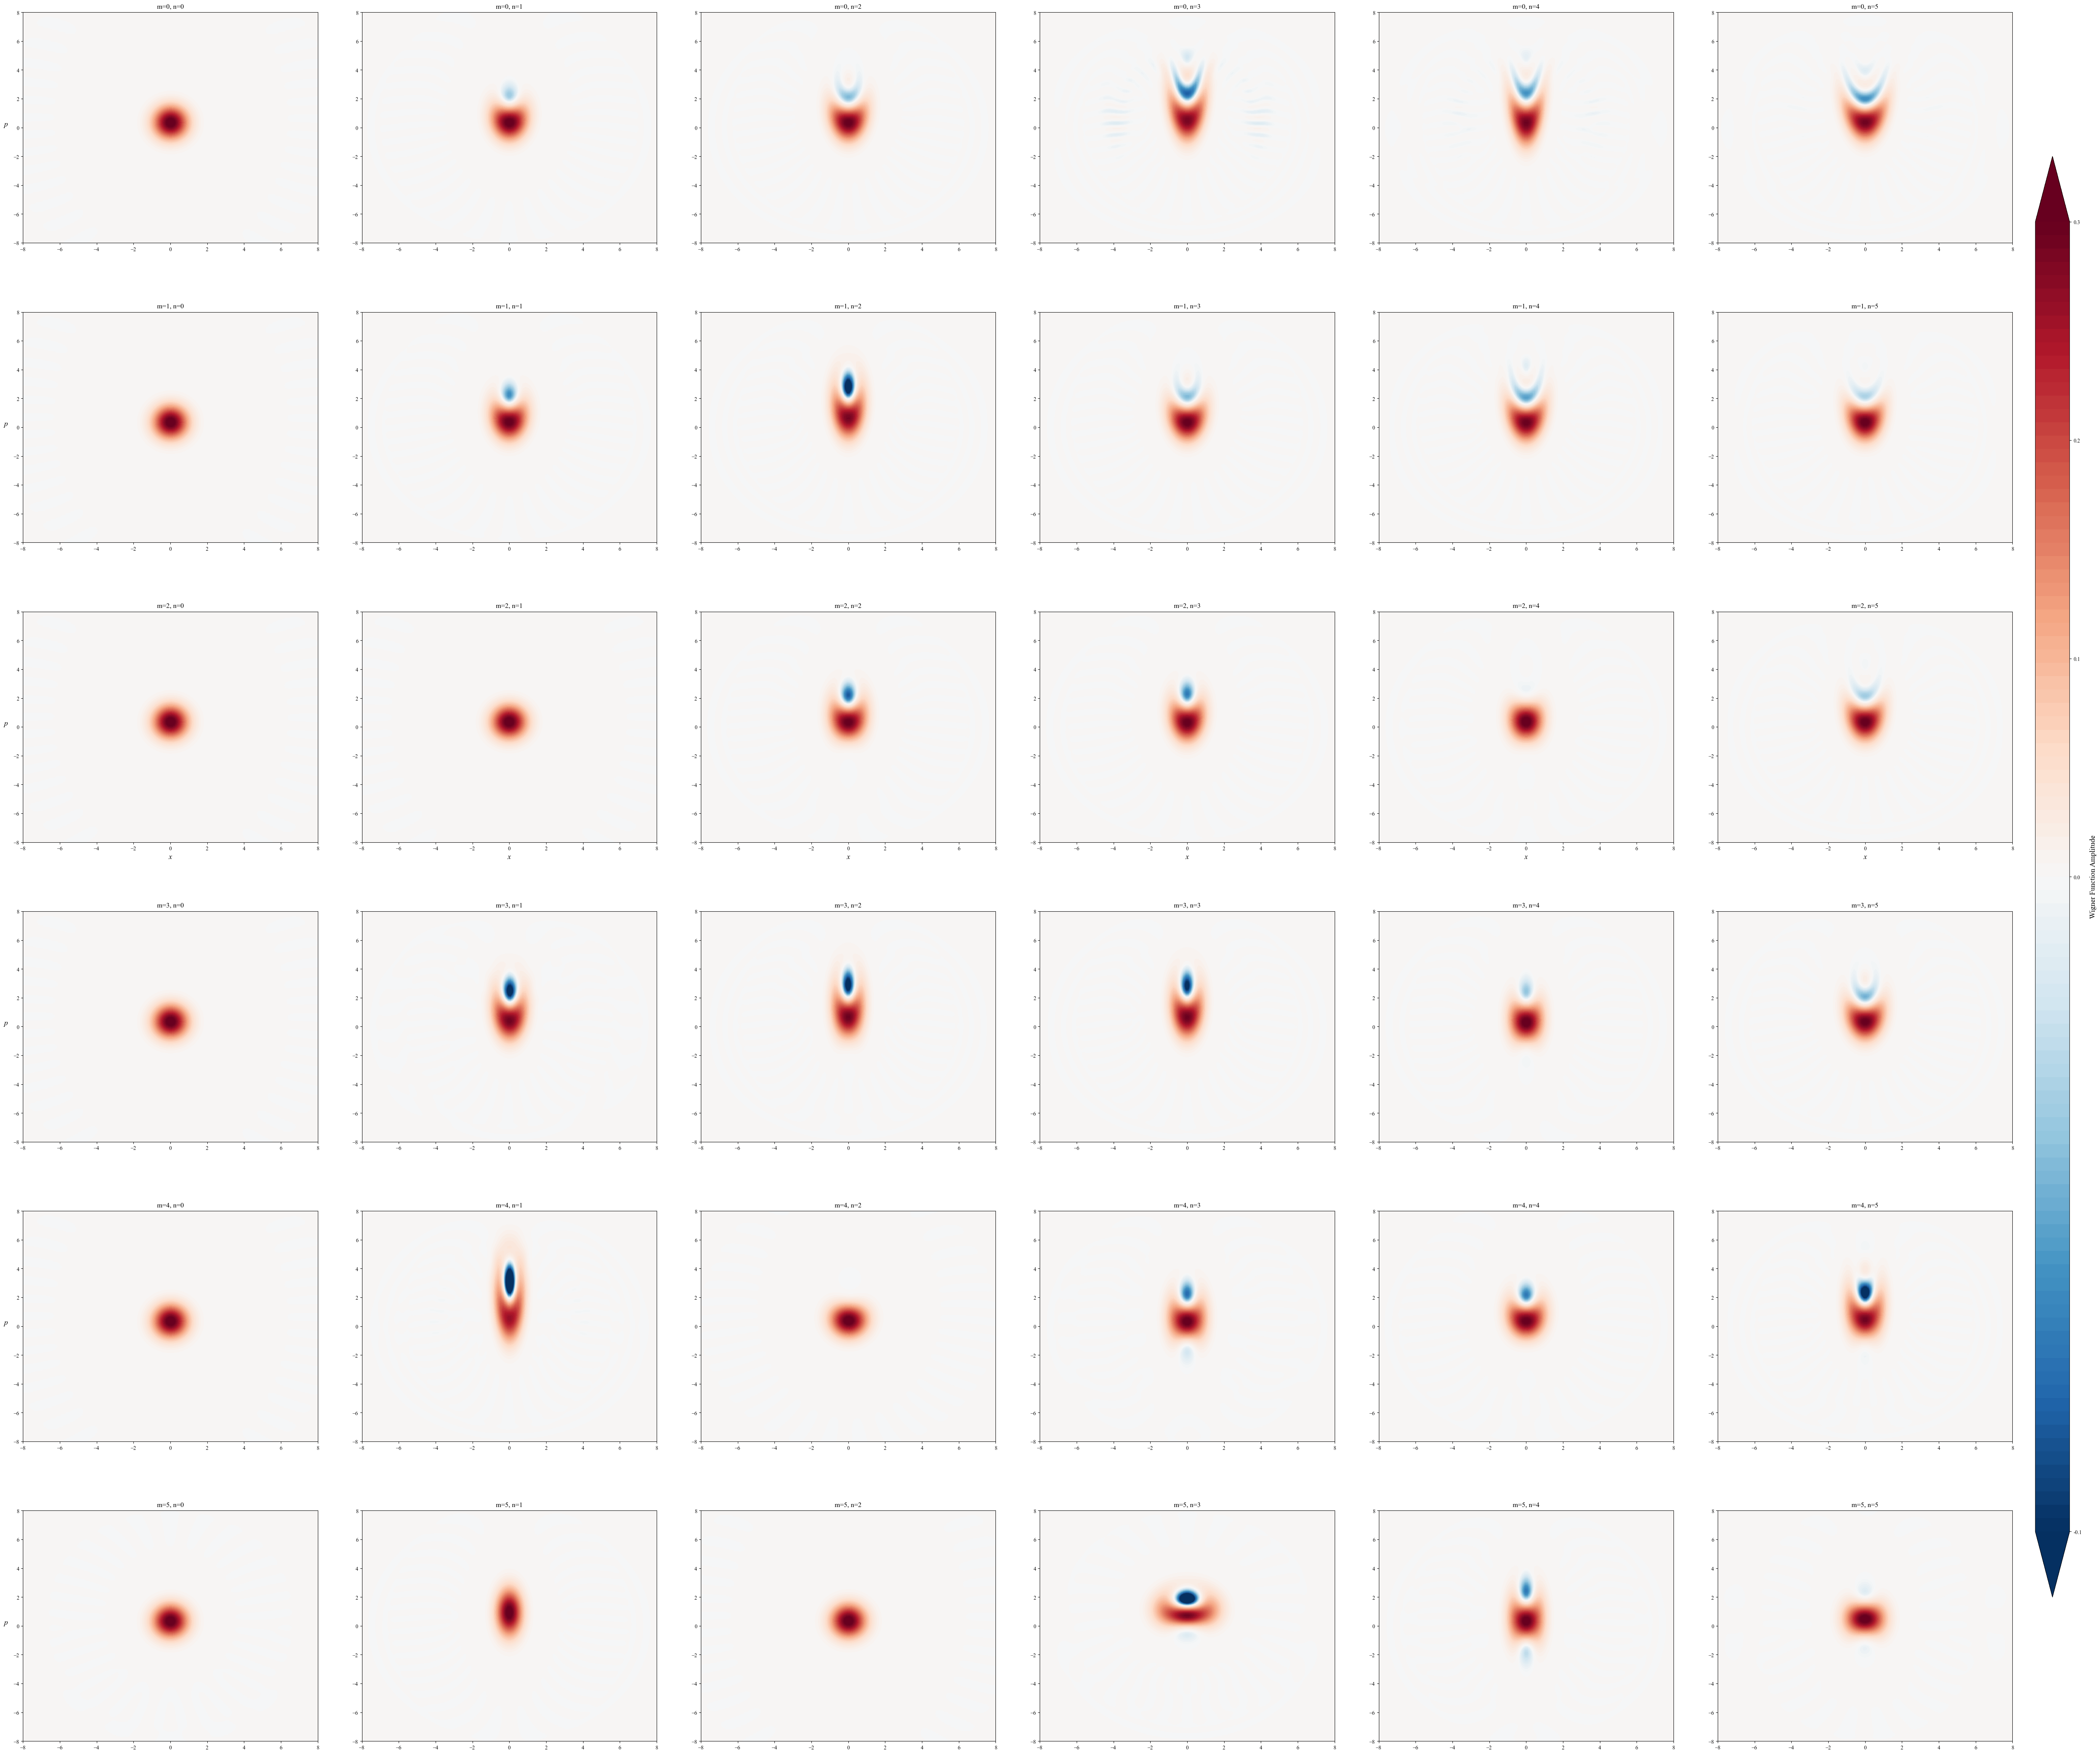

In [3]:
import numpy as np
import math
import qutip as qt
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm
import matplotlib.colors as mcolors
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')

# ========== 1. 样式配置 ==========
plt.style.use('seaborn-v0_8-muted')
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman'],
    'mathtext.fontset': 'cm'
})

# ========== 2. 核心量子算符与操作 ==========
def displacement_operator(alpha, N_dim):
    """生成位移算符 D(alpha)"""
    a = qt.destroy(N_dim)
    D = (alpha * a.dag() - np.conj(alpha) * a).expm()
    return D

def squeezing_operator(r, phi, N_dim):
    """生成单模压缩算符 S(r, phi)"""
    a = qt.destroy(N_dim)
    S = ((r/2) * (np.exp(-1j*phi) * a * a - np.exp(1j*phi) * a.dag() * a.dag())).expm()
    return S

def apply_gaussian_correction(state, r_corr, beta_corr, phi=0):
    """对态施加修正操作: S(r) D(β) ρ D†(β) S†(r)"""
    N_dim = state.shape[0]
    D_beta = displacement_operator(beta_corr, N_dim)
    S_r = squeezing_operator(r_corr, phi, N_dim)
    
    if state.isket:
        rho = state * state.dag()
        corrected_rho = S_r * D_beta * rho * D_beta.dag() * S_r.dag()
        return corrected_rho
    else:
        corrected_state = S_r * D_beta * state * D_beta.dag() * S_r.dag()
        return corrected_state

def ideal_cubic_phase_state(gamma, r_ideal, N_dim):
    """
    目标态定义为立方相位算符作用在压缩真空态上
    O = exp(i*gamma*x^3) * S(r_ideal) |0>
    """
    a = qt.destroy(N_dim)
    x = a + a.dag()
    
    S_op = qt.squeeze(N_dim, r_ideal)
    O = (1j * gamma * x**3).expm()
    
    # 作用在压缩真空态上并归一化
    psi = (O * S_op * qt.fock(N_dim, 0)).unit()
    return psi

def generate_single_opa_state(g_val, alpha, m, n, N_dim=50):
    """生成单个 (m,n) 的 OPA 输出态"""
    g = g_val
    G = np.sqrt(1 - 1 / (g**2))
    
    a = qt.destroy(N_dim)
    adag = a.dag()
    
    g_op_diag = [g**(-j) for j in range(N_dim)]
    g_op = qt.Qobj(np.diag(g_op_diag), dims=[[N_dim], [N_dim]])
    
    initial_state = qt.coherent(N_dim, alpha)
    
    psi_out = qt.basis(N_dim, 0) * 0.0
    for k in range(m + 1):
        if n - m + k < 0:
            continue
        num1 = (-1)**(n - m + k)
        den1 = g**(m - k + 1)
        num2 = (G**(n - m + 2 * k)) * math.sqrt(math.factorial(n) * math.factorial(m))
        den2 = math.factorial(k) * math.factorial(n - m + k) * math.factorial(m - k)
        coef = (num1 / den1) * (num2 / den2)
        term_state = coef * (adag**(n - m + k)) * g_op * (a**k) * initial_state
        psi_out += term_state
    
    return psi_out.unit()

def compute_fidelity(params, m, n, N_dim):
    """计算保真度（恢复 8 维参数优化）"""
    g_val = params[0]
    gamma = params[1]
    r_corr = params[2]
    beta_corr = params[3] + 1j * params[4]
    alpha = params[5] + 1j * params[6]
    r_ideal = params[7]
    
    # ===== 修改点 1：为 g 设立小范围物理护栏 [1.03, 1.5] =====
    if g_val < 1.03 or g_val > 1.50: return 1.0  
    
    # 保持 gamma > 0
    if gamma <= 0.1 or gamma > 2.0: return 1.0  
    if r_corr < -4 or r_corr > 4: return 1.0
    if abs(beta_corr) > 6: return 1.0
    if abs(alpha) > 6: return 1.0
    
    # 保持 r_ideal < 0
    if r_ideal >= 0.0 or r_ideal < -4.0: return 1.0 
    
    try:
        psi_raw = generate_single_opa_state(g_val, alpha, m, n, N_dim)
        psi_corrected = apply_gaussian_correction(psi_raw, r_corr, beta_corr)
        psi_ideal = ideal_cubic_phase_state(gamma, r_ideal, N_dim)
        
        if psi_corrected.isket:
            fid = qt.fidelity(psi_corrected, psi_ideal)**2
        else:
            eigvals, eigstates = psi_corrected.eigenstates()
            idx = np.argmax(eigvals)
            psi_ket = eigstates[idx]
            fid = qt.fidelity(psi_ket, psi_ideal)**2
        
        return 1.0 - fid
    except:
        return 1.0

def optimize_for_mn(m, n, N_dim, maxiter=800):
    """优化特定 (m,n) 组合的参数 (8 维高精度寻优)"""
    
    # 初始猜测，g 的起点放在 1.1，gamma 设为正数 0.3，r_ideal 设为负数 -0.8
    initial_guess = [1.1, 0.3, 0.5, 0.0, 2.5, 0.0, -1.3, -0.8]
    
    # ===== 修改点 2：加入 xatol 和 fatol 强制要求极高精度的收敛 =====
    result = minimize(
        compute_fidelity,
        initial_guess,
        args=(m, n, N_dim),
        method='Nelder-Mead',
        options={
            'maxiter': maxiter, 
            'xatol': 1e-5,   # 变量收敛精度
            'fatol': 1e-5,   # 函数值收敛精度
            'disp': False
        }
    )
    
    opt_fidelity = 1.0 - result.fun
    
    return {
        'm': m,
        'n': n,
        'g_val': result.x[0],
        'gamma': result.x[1],
        'r_corr': result.x[2],
        'beta_corr': result.x[3] + 1j * result.x[4],
        'alpha': result.x[5] + 1j * result.x[6],
        'r_ideal': result.x[7],  
        'fidelity': opt_fidelity
    }

# ========== 3. 控制台打印数据汇总 ==========
def print_summary_table(results_dict, m_values, n_values):
    """在控制台打印所有优化结果的数据表格"""
    print("\n" + "=" * 115)
    print(f"{'m':<3} | {'n':<3} | {'Fidelity':<8} | {'g':<6} | {'gamma':<6} | {'r_ideal':<8} | {'alpha':<18} | {'r_corr':<7} | {'D_corr (beta)':<18}")
    print("-" * 115)
    for m in m_values:
        for n in n_values:
            if (m, n) in results_dict:
                r = results_dict[(m, n)]
                if r['fidelity'] < 0.01:
                    print(f"{m:<3} | {n:<3} | {'OPT FAILED':<8}")
                    continue
                
                # 提取复数
                alpha_r, alpha_i = np.real(r['alpha']), np.imag(r['alpha'])
                alpha_str = f"{alpha_r:.3f}{alpha_i:+.3f}j"
                
                beta_r, beta_i = np.real(r['beta_corr']), np.imag(r['beta_corr'])
                disp_str = f"{beta_r:.3f}{beta_i:+.3f}j"
                
                # 打印单行数据
                print(f"{m:<3} | {n:<3} | {r['fidelity']:.5f} | {r['g_val']:.3f}  | {r['gamma']:.4f} | {r['r_ideal']:.4f}   | {alpha_str:<18} | {r['r_corr']:.4f}  | {disp_str:<18}")
    print("=" * 115 + "\n")


# ========== 4. 绘图与可视化核心逻辑 ==========
def plot_3x5_wigner_grid(results_dict, N_dim=40):
    """
    绘制 3x5 (m=0~2, n=1~5) 的 OPA 修正态 Wigner 函数网格
    """
    m_values = [0, 1, 2, 3, 4, 5]
    n_values = [0, 1, 2, 3, 4, 5]
    
    fig, axes = plt.subplots(6, 6, figsize=(60, 54))
    x_range = 8
    xvec = np.linspace(-x_range, x_range, 120)
    
    print("正在生成 Wigner 函数数据用于绘图...")
    W_dict = {}
    
    for m in m_values:
        for n in n_values:
            if (m, n) in results_dict:
                r = results_dict[(m, n)]
                if r['fidelity'] < 0.01: continue 
                
                psi_raw = generate_single_opa_state(r['g_val'], r['alpha'], m, n, N_dim)
                psi_corr = apply_gaussian_correction(psi_raw, r['r_corr'], r['beta_corr'])
                
                if not psi_corr.isket:
                    eigvals, eigstates = psi_corr.eigenstates()
                    psi_corr = eigstates[np.argmax(eigvals)]
                    
                W = qt.wigner(psi_corr, xvec, xvec)
                W_dict[(m, n)] = W

    # ================= 色条与高分辨率渲染控制区 =================
    vmin = -0.1
    vmax = 0.3
    
    norm = TwoSlopeNorm(vcenter=0.0, vmin=vmin, vmax=vmax)
    
    neg_levels = np.linspace(vmin, 0, 50)
    pos_levels = np.linspace(0, vmax, 50)[1:] 
    levels = np.concatenate([neg_levels, pos_levels])
    cmap = 'RdBu_r'
    # ============================================================

    for i, m in enumerate(m_values):
        for j, n in enumerate(n_values):
            ax = axes[i, j]
            
            if (m, n) in W_dict:
                W = W_dict[(m, n)]
                ax.contourf(xvec, xvec, W, levels=levels, cmap=cmap, norm=norm, extend='both')
                
                # 保留标题标签
                ax.set_title(f"m={m}, n={n}", fontsize=13, pad=8)
            else:
                ax.text(0.5, 0.5, "Data Missing/Failed", ha='center', va='center', transform=ax.transAxes)
                ax.set_title(f"m={m}, n={n}", fontsize=13, pad=8)
            
            ax.set_xlim(-x_range, x_range)
            ax.set_ylim(-x_range, x_range)
            ax.tick_params(labelsize=10)
            
            if i == 2:
                ax.set_xlabel('x', fontsize=14, fontstyle='italic')
            if j == 0:
                ax.set_ylabel('p', fontsize=14, fontstyle='italic', rotation=0, labelpad=15)
                
    plt.subplots_adjust(left=0.05, right=0.92, bottom=0.08, top=0.92, wspace=0.15, hspace=0.3)
    
    # ================= 颜色条排版区 =================
    cbar_ax = fig.add_axes([0.93, 0.15, 0.015, 0.7])
    cbar_ticks = [-0.1, 0.0, 0.1, 0.2, 0.3]
    cbar = fig.colorbar(axes[0, 0].collections[0], cax=cbar_ax, ticks=cbar_ticks)
    cbar.ax.set_ylabel('Wigner Function Amplitude', fontsize=14, rotation=90, labelpad=15)
    cbar.ax.set_yticklabels([f"{t:.1f}" for t in cbar_ticks], fontsize=10)
    # ====================================================
    
    plt.show()

# =====================================================================
# 主程序执行入口
# =====================================================================
if __name__ == "__main__":
    
    m_values = [0, 1, 2, 3, 4, 5]
    n_values = [0, 1, 2, 3, 4, 5]
    
    N_DIM_OPT = 20    # 优化维数
    N_DIM_PLOT = 35   # 绘图维数
    
    print("=" * 80)
    print(f"准备优化 15 种组合 (m=0~2, n=1~5)")
    print(f"【物理设定】：OPA增益 g 在 [1.03, 1.5] 内高精度寻优，目标态 r_ideal < 0，gamma > 0，请耐心等待...")
    print("=" * 80)
    
    results = {}
    
    for m in m_values:
        for n in n_values:
            print(f"-> 正在优化 (m={m}, n={n}) ...", end=" ", flush=True)
            # 调用时去掉了 g_fixed 参数，并将 maxiter 提升至 800
            result = optimize_for_mn(m, n, N_DIM_OPT, maxiter=800)
            results[(m, n)] = result
            print(f"完成! F={result['fidelity']:.4f} | g={result['g_val']:.3f}")
    
    # 打印终端汇总表格
    print_summary_table(results, m_values, n_values)
    
    print("开始绘制 3x5 Wigner 函数矩阵...")
    plot_3x5_wigner_grid(results, N_dim=N_DIM_PLOT)

准备开始 [多起点强寻优] 4 种组合: [(1, 1), (2, 2), (3, 3), (4, 4)]
【物理设定】：OPA增益 g 在 [1.01, 1.50] 内密集轰炸寻优，避免陷入局部最优...
核心算法每组均从 8 个不同初始点出发，最大迭代 800 次，请耐心等待。
成功! 压榨出最高保真度 F=0.9756, 最佳 g=1.083
成功! 压榨出最高保真度 F=0.9927, 最佳 g=2.059
成功! 压榨出最高保真度 F=0.9925, 最佳 g=2.338
成功! 压榨出最高保真度 F=0.9890, 最佳 g=2.473

m   | n   | Fidelity | g      | gamma  | r_ideal  | alpha              | r_corr  | D_corr (beta)     
-------------------------------------------------------------------------------------------------------------------
1   | 1   | 0.97562 | 1.083  | 0.1000 | -0.0000   | 0.003-4.136j       | 0.2033  | 0.010+4.406j      
2   | 2   | 0.99265 | 2.059  | 0.1001 | -0.0001   | -0.002-3.676j      | 0.3995  | 0.002+2.786j      
3   | 3   | 0.99249 | 2.338  | 0.1283 | -0.0000   | -0.005-3.933j      | 0.5265  | 0.001+3.020j      
4   | 4   | 0.98903 | 2.473  | 0.1662 | -0.0111   | -0.003-3.960j      | 0.6474  | -0.009+3.258j     

开始基于多起点优化数据，绘制 2x2 完美裁剪视角 Wigner 矩阵...
正在生成范围在 x:[-5, 5], p:[-2, 8] 内的 Wigner 函数数据...


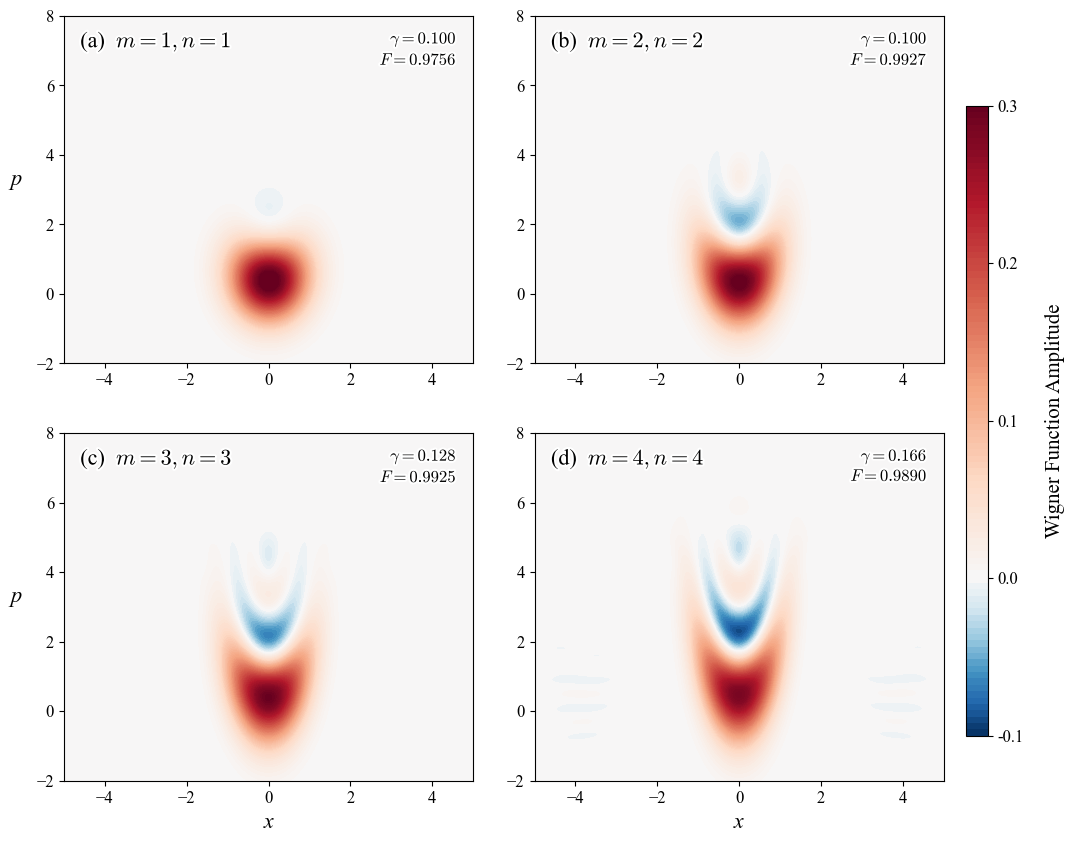

In [3]:
import numpy as np
import math
import qutip as qt
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patheffects as pe
from scipy.optimize import minimize
import warnings
warnings.filterwarnings('ignore')

# ========== 1. 样式配置 ==========
plt.style.use('seaborn-v0_8-muted')
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman'],
    'mathtext.fontset': 'cm'
})

# ========== 2. 核心量子算符与操作 ==========
def displacement_operator(alpha, N_dim):
    """生成位移算符 D(alpha)"""
    a = qt.destroy(N_dim)
    D = (alpha * a.dag() - np.conj(alpha) * a).expm()
    return D

def squeezing_operator(r, phi, N_dim):
    """生成单模压缩算符 S(r, phi)"""
    a = qt.destroy(N_dim)
    S = ((r/2) * (np.exp(-1j*phi) * a * a - np.exp(1j*phi) * a.dag() * a.dag())).expm()
    return S

def apply_gaussian_correction(state, r_corr, beta_corr, phi=0):
    """对态施加修正操作: S(r) D(β) ρ D†(β) S†(r)"""
    N_dim = state.shape[0]
    D_beta = displacement_operator(beta_corr, N_dim)
    S_r = squeezing_operator(r_corr, phi, N_dim)
    
    if state.isket:
        rho = state * state.dag()
        corrected_rho = S_r * D_beta * rho * D_beta.dag() * S_r.dag()
        return corrected_rho
    else:
        corrected_state = S_r * D_beta * state * D_beta.dag() * S_r.dag()
        return corrected_state

def ideal_cubic_phase_state(gamma, r_ideal, N_dim):
    """
    目标态定义为立方相位算符作用在压缩真空态上
    O = exp(i*gamma*x^3) * S(r_ideal) |0>
    """
    a = qt.destroy(N_dim)
    x = a + a.dag()
    
    S_op = qt.squeeze(N_dim, r_ideal)
    O = (1j * gamma * x**3).expm()
    
    # 作用在压缩真空态上并归一化
    psi = (O * S_op * qt.fock(N_dim, 0)).unit()
    return psi

def generate_single_opa_state(g_val, alpha, m, n, N_dim=50):
    """生成单个 (m,n) 的 OPA 输出态"""
    g = g_val
    G = np.sqrt(1 - 1 / (g**2))
    
    a = qt.destroy(N_dim)
    adag = a.dag()
    
    g_op_diag = [g**(-j) for j in range(N_dim)]
    g_op = qt.Qobj(np.diag(g_op_diag), dims=[[N_dim], [N_dim]])
    
    initial_state = qt.coherent(N_dim, alpha)
    
    psi_out = qt.basis(N_dim, 0) * 0.0
    for k in range(m + 1):
        if n - m + k < 0:
            continue
        num1 = (-1)**(n - m + k)
        den1 = g**(m - k + 1)
        num2 = (G**(n - m + 2 * k)) * math.sqrt(math.factorial(n) * math.factorial(m))
        den2 = math.factorial(k) * math.factorial(n - m + k) * math.factorial(m - k)
        coef = (num1 / den1) * (num2 / den2)
        term_state = coef * (adag**(n - m + k)) * g_op * (a**k) * initial_state
        psi_out += term_state
    
    return psi_out.unit()

def compute_fidelity(params, m, n, N_dim):
    """计算保真度代价函数"""
    g_val = params[0]
    gamma = params[1]
    r_corr = params[2]
    beta_corr = params[3] + 1j * params[4]
    alpha = params[5] + 1j * params[6]
    r_ideal = params[7]
    
    # 物理边界约束（采用代码二的 OPA 增益限制，锁死在低/中增益高物理价值区）
    if g_val < 1.01 or g_val > 5: return 1.0
    if gamma <= 0.1 or gamma > 2.0: return 1.0  
    if r_corr < -4 or r_corr > 4: return 1.0
    if abs(beta_corr) > 6: return 1.0
    if abs(alpha) > 6: return 1.0
    if r_ideal >= -0.0 or r_ideal < -4.0: return 1.0 
    
    try:
        psi_raw = generate_single_opa_state(g_val, alpha, m, n, N_dim)
        psi_corrected = apply_gaussian_correction(psi_raw, r_corr, beta_corr)
        psi_ideal = ideal_cubic_phase_state(gamma, r_ideal, N_dim)
        
        if psi_corrected.isket:
            fid = qt.fidelity(psi_corrected, psi_ideal)**2
        else:
            eigvals, eigstates = psi_corrected.eigenstates()
            idx = np.argmax(eigvals)
            psi_ket = eigstates[idx]
            fid = qt.fidelity(psi_ket, psi_ideal)**2
        
        return 1.0 - fid
    except:
        return 1.0

def optimize_for_mn(m, n, N_dim, maxiter=800):
    """核心修改点：升级为多起点 Nelder-Mead 寻优策略，最大迭代提升至 800"""
    initial_guesses = [
        [1.2, 0.12, 0.3,  0.0,  4.9,  0.0, -1.3, -0.05],   # 极低增益区
        [1.4, 0.12, 0.3,  0.0,  4.9,  0.0, -1.3, -0.05],   # 集中区域
        [1.5, 0.15, 0.4,  0.0,  4.5,  0.0, -1.3, -0.05],
        [1.6, 0.20, 0.5,  0.0,  3.5,  0.0, -1.3, -0.30],
        [1.8, 0.25, 0.5,  0.0,  3.0,  0.0, -1.3, -0.50],
        [1.9, 0.30, 0.5,  0.0,  2.5,  0.0, -1.3, -0.80],   # 经典原点
        [2.2, 0.30, 0.5,  0.0,  2.5,  0.0, -1.3, -0.80],
        [2.4, 0.30, 0.5,  0.0,  2.5,  0.0, -1.3, -0.80],
    ]
    
    best_result = None
    best_fidelity = -1.0
    
    for guess in initial_guesses:
        try:
            res = minimize(
                compute_fidelity,
                guess,
                args=(m, n, N_dim),
                method='Nelder-Mead',
                options={
                    'maxiter': maxiter, 
                    'xatol': 1e-5,
                    'fatol': 1e-5,
                    'disp': False
                }
            )
            fid = 1.0 - res.fun
            if fid > best_fidelity:
                best_fidelity = fid
                best_result = res
        except:
            continue
            
    return {
        'm': m,
        'n': n,
        'g_val': best_result.x[0],
        'gamma': best_result.x[1],
        'r_corr': best_result.x[2],
        'beta_corr': best_result.x[3] + 1j * best_result.x[4],
        'alpha': best_result.x[5] + 1j * best_result.x[6],
        'r_ideal': best_result.x[7],  
        'fidelity': best_fidelity
    }

# ========== 3. 控制台打印数据汇总 ==========
def print_summary_table(results_dict, selected_pairs):
    """在控制台打印精选组合的优化结果数据表格"""
    print("\n" + "=" * 115)
    print(f"{'m':<3} | {'n':<3} | {'Fidelity':<8} | {'g':<6} | {'gamma':<6} | {'r_ideal':<8} | {'alpha':<18} | {'r_corr':<7} | {'D_corr (beta)':<18}")
    print("-" * 115)
    
    for (m, n) in selected_pairs:
        if (m, n) in results_dict:
            r = results_dict[(m, n)]
            if r['fidelity'] < 0.01:
                print(f"{m:<3} | {n:<3} | {'OPT FAILED':<8}")
                continue
            
            alpha_r, alpha_i = np.real(r['alpha']), np.imag(r['alpha'])
            alpha_str = f"{alpha_r:.3f}{alpha_i:+.3f}j"
            
            beta_r, beta_i = np.real(r['beta_corr']), np.imag(r['beta_corr'])
            disp_str = f"{beta_r:.3f}{beta_i:+.3f}j"
            
            print(f"{m:<3} | {n:<3} | {r['fidelity']:.5f} | {r['g_val']:.3f}  | {r['gamma']:.4f} | {r['r_ideal']:.4f}   | {alpha_str:<18} | {r['r_corr']:.4f}  | {disp_str:<18}")
    print("=" * 115 + "\n")

# ========== 4. 色条与绘图核心逻辑 ==========
def get_asymmetric_cmap(vmin, vmax, name='RdBu_r'):
    """构建非对称 colormap，确保 0 点正好在纯白色"""
    cmap_base = plt.get_cmap(name)
    zero_ratio = (0.0 - vmin) / (vmax - vmin) 
    
    n_blue = int(256 * zero_ratio)
    n_red = 256 - n_blue
    
    blue_colors = cmap_base(np.linspace(0.0, 0.5, n_blue))
    red_colors = cmap_base(np.linspace(0.5, 1.0, n_red))
    
    all_colors = np.vstack((blue_colors, red_colors))
    return mcolors.LinearSegmentedColormap.from_list('shifted_cmap', all_colors)

def plot_2x2_selected_wigner(results_dict, selected_pairs, N_dim=40):
    """绘制选定的 4 张 Wigner 函数图 (2x2 网格)"""
    labels = ['(a)', '(b)', '(c)', '(d)']
    
    fig, axes = plt.subplots(2, 2, figsize=(11, 9))
    axes = axes.flatten() 
    
    # 保持代码一的长方形物理范围优势（沿 p 轴拉伸，完美契合立方相位态特征）
    x_min, x_max = -5, 5
    y_min, y_max = -2, 8
    
    xvec = np.linspace(x_min, x_max, 200) 
    yvec = np.linspace(y_min, y_max, 200) 
    
    print(f"正在生成范围在 x:[{x_min}, {x_max}], p:[{y_min}, {y_max}] 内的 Wigner 函数数据...")

    vmin = -0.1
    vmax = 0.3
    levels = np.linspace(vmin, vmax, 100)
    custom_cmap = get_asymmetric_cmap(vmin, vmax, 'RdBu_r')
    text_outline = [pe.withStroke(linewidth=3, foreground='white')]

    for idx, (m, n) in enumerate(selected_pairs):
        ax = axes[idx]
        
        if (m, n) in results_dict:
            r = results_dict[(m, n)]
            if r['fidelity'] >= 0.01:
                # 重新生成高维度的态用于绘图
                psi_raw = generate_single_opa_state(r['g_val'], r['alpha'], m, n, N_dim)
                psi_corr = apply_gaussian_correction(psi_raw, r['r_corr'], r['beta_corr'])
                
                if not psi_corr.isket:
                    eigvals, eigstates = psi_corr.eigenstates()
                    psi_corr = eigstates[np.argmax(eigvals)]
                    
                W = qt.wigner(psi_corr, xvec, yvec)
                W_clipped = np.clip(W, vmin, vmax)
                
                ax.contourf(xvec, yvec, W_clipped, levels=levels, cmap=custom_cmap)
                
                # 左上角标签
                left_text = f"{labels[idx]}  $m={m}, n={n}$"
                ax.text(0.04, 0.96, left_text, transform=ax.transAxes,
                        fontsize=16, verticalalignment='top', horizontalalignment='left',
                        path_effects=text_outline, color='black')
                
                # 右上角标签 (显示全局最优得到的 gamma 和保真度 F)
                right_text = f"$\gamma={r['gamma']:.3f}$\n$F={r['fidelity']:.4f}$"
                ax.text(0.96, 0.96, right_text, transform=ax.transAxes,
                        fontsize=12, verticalalignment='top', horizontalalignment='right',
                        path_effects=text_outline, color='black')
                
            else:
                ax.text(0.5, 0.5, "Data Missing/Failed", ha='center', va='center', transform=ax.transAxes)
                ax.set_title(f"{labels[idx]} m={m}, n={n} (Failed)", fontsize=14)
        
        ax.set_xlim(x_min, x_max)
        ax.set_ylim(y_min, y_max)
        ax.tick_params(labelsize=12)
        
        if idx >= 2:
            ax.set_xlabel('x', fontsize=16, fontstyle='italic')
        if idx % 2 == 0:
            ax.set_ylabel('p', fontsize=16, fontstyle='italic', rotation=0, labelpad=15)
            
    plt.subplots_adjust(left=0.08, right=0.88, bottom=0.1, top=0.95, wspace=0.15, hspace=0.2)
    
    # 颜色条排版
    cbar_ax = fig.add_axes([0.9, 0.15, 0.02, 0.7]) 
    cbar_ticks = [-0.1, 0.0, 0.1, 0.2, 0.3]
    cbar = fig.colorbar(axes[0].collections[0], cax=cbar_ax, ticks=cbar_ticks)
    cbar.ax.set_ylabel('Wigner Function Amplitude', fontsize=15, rotation=90, labelpad=15)
    cbar.ax.set_yticklabels([f"{t:.1f}" for t in cbar_ticks], fontsize=12)
    
    plt.show()

# =====================================================================
# 主程序执行入口
# =====================================================================
if __name__ == "__main__":
    
    selected_pairs = [
        (1, 1),  # 子图 (a)
        (2, 2),  # 子图 (b)
        (3, 3),  # 子图 (c)
        (4, 4),  # 子图 (d)
    ]
    
    N_DIM_OPT = 20    # 优化维数 (与代码二对齐提升运算效率)
    N_DIM_PLOT = 40   # 绘图维数 (保证画图分辨率与精细度)
    
    print("=" * 80)
    print(f"准备开始 [多起点强寻优] 4 种组合: {selected_pairs}")
    print(f"【物理设定】：OPA增益 g 在 [1.01, 1.50] 内密集轰炸寻优，避免陷入局部最优...")
    print(f"核心算法每组均从 8 个不同初始点出发，最大迭代 800 次，请耐心等待。")
    print("=" * 80)
    
    results = {}
    
    for (m, n) in selected_pairs:
        print(f"-> 正在进行多起点寻优 (m={m}, n={n}) ...", end=" ", flush=True)
        result = optimize_for_mn(m, n, N_DIM_OPT, maxiter=800)
        results[(m, n)] = result
        print(f"成功! 压榨出最高保真度 F={result['fidelity']:.4f}, 最佳 g={result['g_val']:.3f}")
    
    # 1. 打印更新后的全局最优终端汇总表格
    print_summary_table(results, selected_pairs)
    
    # 2. 开始绘制完美视角的 2x2 Wigner 函数图
    print("开始基于多起点优化数据，绘制 2x2 完美裁剪视角 Wigner 矩阵...")
    plot_2x2_selected_wigner(results, selected_pairs, N_dim=N_DIM_PLOT)

正在直接读取参数，无需重新寻优，秒速计算并绘图...

【参数已修正】：alpha 和 D_corr(beta) 的实部已强制抹除，以下为重新计算的纯虚数保真度
-------------------------------------------------------------------------------------------------------------------
m   | n   | Fidelity | g      | gamma  | r_ideal  | alpha              | r_corr  | D_corr (beta)     
-------------------------------------------------------------------------------------------------------------------
1   | 1   | 0.97517 | 1.083  | 0.1000 | -0.0000   | 0.000-4.136j       | 0.2033  | 0.000+4.406j      
2   | 2   | 0.99270 | 2.059  | 0.1001 | -0.0001   | 0.000-3.676j       | 0.3995  | 0.000+2.786j      
3   | 3   | 0.99180 | 2.338  | 0.1283 | -0.0000   | 0.000-3.933j       | 0.5265  | 0.000+3.020j      
4   | 4   | 0.98744 | 2.473  | 0.1662 | -0.0111   | 0.000-3.960j       | 0.6474  | 0.000+3.258j      



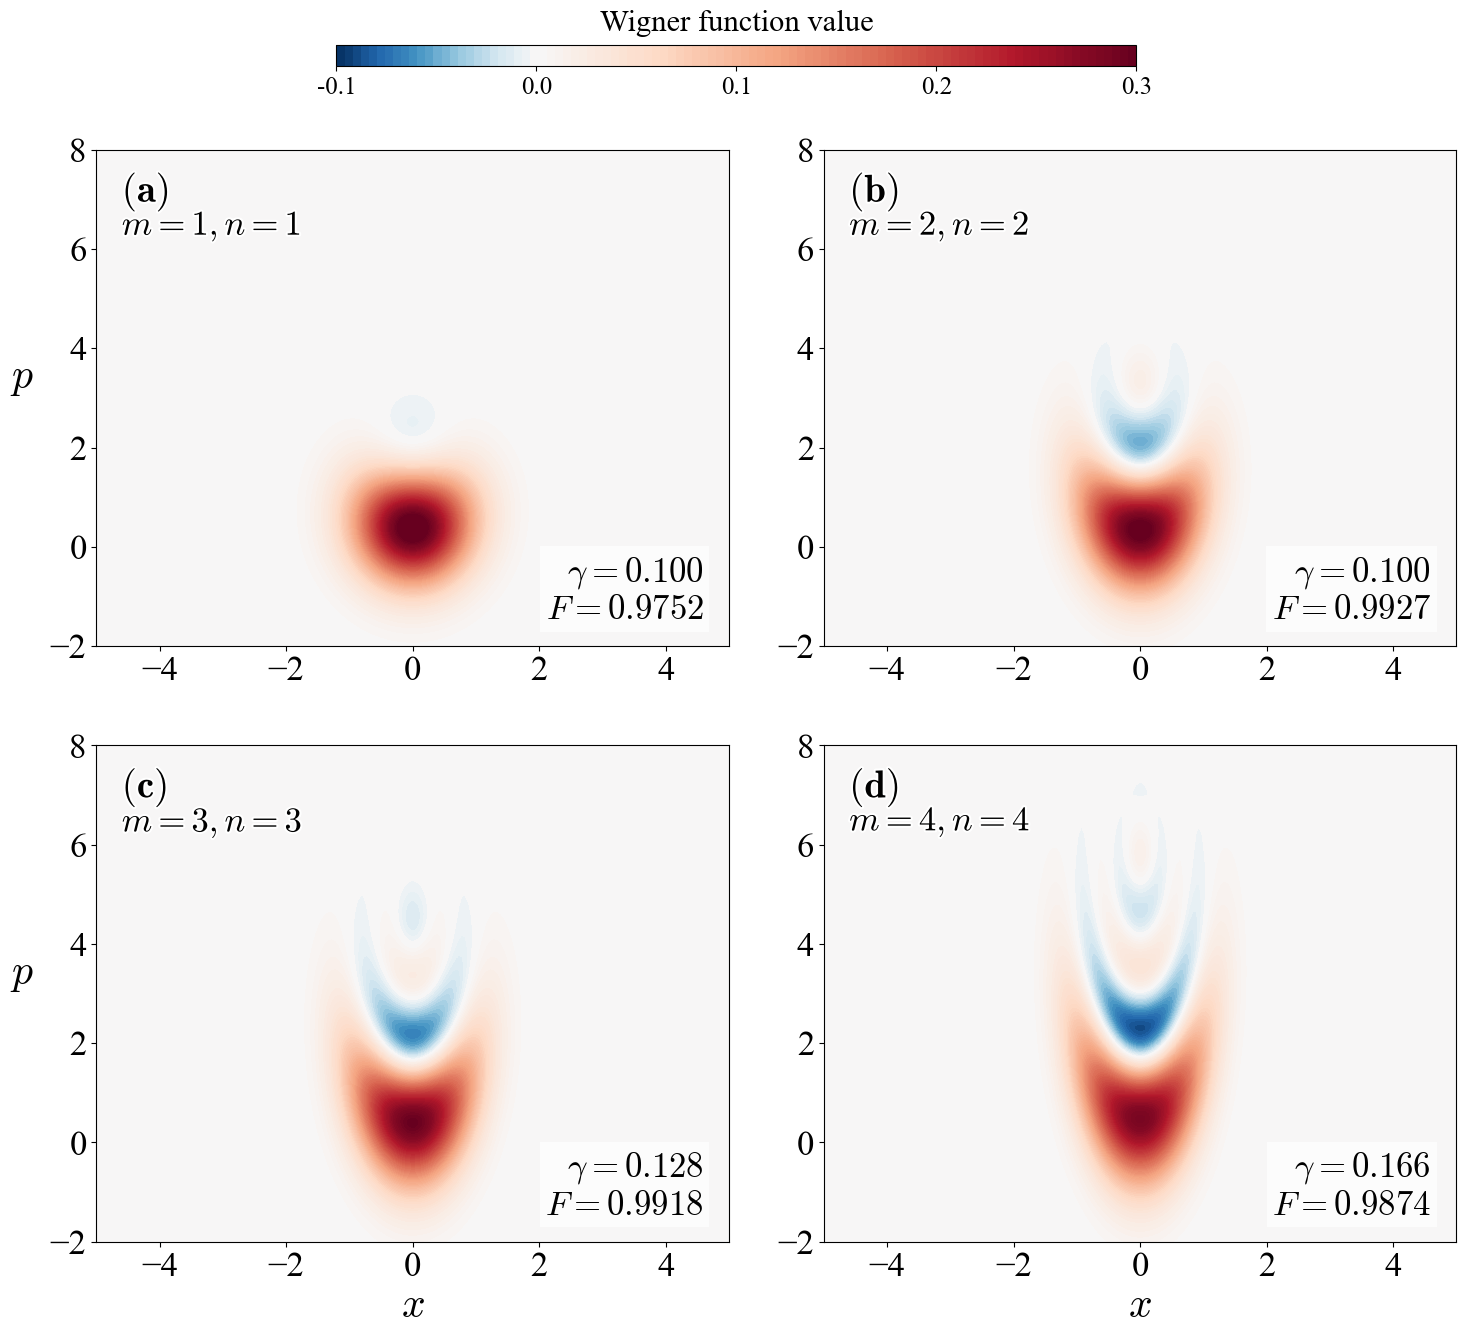

In [9]:
import numpy as np
import math
import qutip as qt
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patheffects as pe
import warnings
warnings.filterwarnings('ignore')

# ============================================================
#  全局尺寸及字号设置
# ============================================================
FIG_SIZE = (16, 14)             # 画布整体物理尺寸 (宽, 高)
LABEL_SIZE = 30                 # x, p 坐标轴标签大小
TICK_SIZE = 25                  # 主图坐标轴数字刻度大小
SUBPLOT_LABEL_SIZE = 28         # (a)(b)(c)(d) 角标字体大小
CASE_LABEL_SIZE = 25            # 物理参数 (m=, n=) 文本大小
EXTRA_INFO_SIZE = 25            # 右下角额外信息 (F=, gamma=) 文本框大小
CBAR_TITLE_SIZE = 22            # 色条标题大小
CBAR_TICK_SIZE = 18             # 色条数字刻度大小

# ========== 1. 样式配置 ==========
plt.style.use('seaborn-v0_8-muted')
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman'],
    'mathtext.fontset': 'cm'
})

# ========== 2. 核心量子算符与操作 ==========
def displacement_operator(alpha, N_dim):
    """生成位移算符 D(alpha)"""
    a = qt.destroy(N_dim)
    D = (alpha * a.dag() - np.conj(alpha) * a).expm()
    return D

def squeezing_operator(r, phi, N_dim):
    """生成单模压缩算符 S(r, phi)"""
    a = qt.destroy(N_dim)
    S = ((r/2) * (np.exp(-1j*phi) * a * a - np.exp(1j*phi) * a.dag() * a.dag())).expm()
    return S

def apply_gaussian_correction(state, r_corr, beta_corr, phi=0):
    """对态施加修正操作"""
    N_dim = state.shape[0]
    D_beta = displacement_operator(beta_corr, N_dim)
    S_r = squeezing_operator(r_corr, phi, N_dim)
    
    # 直接维持纯态演化，速度极快且无舍入误差
    if state.isket:
        return S_r * D_beta * state
    else:
        return S_r * D_beta * state * D_beta.dag() * S_r.dag()

def ideal_cubic_phase_state(gamma, r_ideal, N_dim):
    """
    目标态定义为立方相位算符作用在压缩真空态上
    O = exp(i*gamma*x^3) * S(r_ideal) |0>
    """
    a = qt.destroy(N_dim)
    x = a + a.dag()
    
    S_op = qt.squeeze(N_dim, r_ideal)
    O = (1j * gamma * x**3).expm()
    
    psi = (O * S_op * qt.fock(N_dim, 0)).unit()
    return psi

def generate_single_opa_state(g_val, alpha, m, n, N_dim=50):
    """生成单个 (m,n) 的 OPA 输出态"""
    g = g_val
    G = np.sqrt(1 - 1 / (g**2))
    
    a = qt.destroy(N_dim)
    adag = a.dag()
    
    g_op_diag = [g**(-j) for j in range(N_dim)]
    g_op = qt.Qobj(np.diag(g_op_diag), dims=[[N_dim], [N_dim]])
    
    initial_state = qt.coherent(N_dim, alpha)
    
    psi_out = qt.basis(N_dim, 0) * 0.0
    for k in range(m + 1):
        if n - m + k < 0:
            continue
        num1 = (-1)**(n - m + k)
        den1 = g**(m - k + 1)
        num2 = (G**(n - m + 2 * k)) * math.sqrt(math.factorial(n) * math.factorial(m))
        den2 = math.factorial(k) * math.factorial(n - m + k) * math.factorial(m - k)
        coef = (num1 / den1) * (num2 / den2)
        term_state = coef * (adag**(n - m + k)) * g_op * (a**k) * initial_state
        psi_out += term_state
    
    return psi_out.unit()

def evaluate_fixed_parameters(fixed_params, N_dim=40):
    """根据给定的写死参数，重新计算去掉实部后的准确保真度"""
    results_dict = {}
    
    for (m, n), params in fixed_params.items():
        psi_raw = generate_single_opa_state(params['g_val'], params['alpha'], m, n, N_dim)
        psi_corrected = apply_gaussian_correction(psi_raw, params['r_corr'], params['beta_corr'])
        psi_ideal = ideal_cubic_phase_state(params['gamma'], params['r_ideal'], N_dim)
        
        fid = qt.fidelity(psi_corrected, psi_ideal)**2
        
        # 将重新计算的保真度写回字典
        params['fidelity'] = fid
        results_dict[(m, n)] = params
        
    return results_dict

# ========== 3. 控制台打印数据汇总 ==========
def print_summary_table(results_dict, selected_pairs):
    """在控制台打印精选组合的优化结果数据表格"""
    print("\n" + "=" * 115)
    print("【参数已修正】：alpha 和 D_corr(beta) 的实部已强制抹除，以下为重新计算的纯虚数保真度")
    print("-" * 115)
    print(f"{'m':<3} | {'n':<3} | {'Fidelity':<8} | {'g':<6} | {'gamma':<6} | {'r_ideal':<8} | {'alpha':<18} | {'r_corr':<7} | {'D_corr (beta)':<18}")
    print("-" * 115)
    
    for (m, n) in selected_pairs:
        r = results_dict[(m, n)]
        alpha_str = f"0.000{np.imag(r['alpha']):+.3f}j"
        disp_str = f"0.000{np.imag(r['beta_corr']):+.3f}j"
        
        print(f"{m:<3} | {n:<3} | {r['fidelity']:.5f} | {r['g_val']:.3f}  | {r['gamma']:.4f} | {r['r_ideal']:.4f}   | {alpha_str:<18} | {r['r_corr']:.4f}  | {disp_str:<18}")
    print("=" * 115 + "\n")

# ========== 4. 色条与绘图核心逻辑 ==========
def get_asymmetric_cmap(vmin, vmax, name='RdBu_r'):
    """构建非对称 colormap"""
    cmap_base = plt.get_cmap(name)
    zero_ratio = (0.0 - vmin) / (vmax - vmin) 
    
    n_blue = int(256 * zero_ratio)
    n_red = 256 - n_blue
    
    blue_colors = cmap_base(np.linspace(0.0, 0.5, n_blue))
    red_colors = cmap_base(np.linspace(0.5, 1.0, n_red))
    
    all_colors = np.vstack((blue_colors, red_colors))
    return mcolors.LinearSegmentedColormap.from_list('shifted_cmap', all_colors)

def plot_2x2_selected_wigner(results_dict, selected_pairs, N_dim=40):
    """绘制选定的 4 张 Wigner 函数图"""
    # 🌟 使用加粗的 LaTeX 标签
    labels = [r'$\mathbf{(a)}$', r'$\mathbf{(b)}$', r'$\mathbf{(c)}$', r'$\mathbf{(d)}$']
    
    # 🌟 应用全局画布尺寸
    fig, axes = plt.subplots(2, 2, figsize=FIG_SIZE)
    axes = axes.flatten() 
    
    x_min, x_max = -5, 5
    y_min, y_max = -2, 8
    
    xvec = np.linspace(x_min, x_max, 200) 
    yvec = np.linspace(y_min, y_max, 200) 
    
    vmin, vmax = -0.1, 0.3
    levels = np.linspace(vmin, vmax, 100)
    custom_cmap = get_asymmetric_cmap(vmin, vmax, 'RdBu_r')
    text_outline = [pe.withStroke(linewidth=3, foreground='white')]

    for idx, (m, n) in enumerate(selected_pairs):
        ax = axes[idx]
        r = results_dict[(m, n)]
        
        psi_raw = generate_single_opa_state(r['g_val'], r['alpha'], m, n, N_dim)
        psi_corr = apply_gaussian_correction(psi_raw, r['r_corr'], r['beta_corr'])
            
        W = qt.wigner(psi_corr, xvec, yvec)
        W_clipped = np.clip(W, vmin, vmax)
        
        ax.contourf(xvec, yvec, W_clipped, levels=levels, cmap=custom_cmap)
        
        # 🌟 左上角角标 (a)(b)(c)(d) - 使用 SUBPLOT_LABEL_SIZE
        ax.text(0.04, 0.96, labels[idx], transform=ax.transAxes,
                fontsize=SUBPLOT_LABEL_SIZE, va='top', ha='left',
                path_effects=text_outline, color='black')
        
        # 🌟 物理参数 - 使用 CASE_LABEL_SIZE (放在角标下方)
        ax.text(0.04, 0.88, f"$m={m}, n={n}$", transform=ax.transAxes,
                fontsize=CASE_LABEL_SIZE, va='top', ha='left',
                path_effects=text_outline, color='black')
        
        # 🌟 右下角参数框 - 使用 EXTRA_INFO_SIZE
        right_text = f"$\\gamma={r['gamma']:.3f}$\n$F={r['fidelity']:.4f}$"
        ax.text(0.96, 0.04, right_text, transform=ax.transAxes,
                fontsize=EXTRA_INFO_SIZE, va='bottom', ha='right',
                bbox=dict(facecolor='white', edgecolor='none', alpha=0.7))
        
        ax.set_xlim(x_min, x_max)
        ax.set_ylim(y_min, y_max)
        
        # 🌟 应用 TICK_SIZE
        ax.tick_params(labelsize=TICK_SIZE)
        
        # 🌟 应用 LABEL_SIZE
        if idx >= 2:
            ax.set_xlabel('$x$', fontsize=LABEL_SIZE)
        if idx % 2 == 0:
            ax.set_ylabel('$p$', fontsize=LABEL_SIZE, rotation=0, labelpad=20)
            
    # 🌟 修改点：调整主图边距，压缩 top 给色条留空间，放大 right
    plt.subplots_adjust(left=0.1, right=0.95, bottom=0.1, top=0.88, wspace=0.15, hspace=0.2)
    
    # 🌟 修改点：色条移至正上方水平放置
    cbar_ax = fig.add_axes([0.25, 0.94, 0.5, 0.015])  # [x, y, width, height]
    cbar_ticks = [-0.1, 0.0, 0.1, 0.2, 0.3]
    cbar = fig.colorbar(axes[0].collections[0], cax=cbar_ax, orientation='horizontal', ticks=cbar_ticks)
    
    # 🌟 修改点：应用 CBAR_TITLE_SIZE 和 CBAR_TICK_SIZE，并将标题移至上方
    cbar.set_label('Wigner function value', fontsize=CBAR_TITLE_SIZE, labelpad=10)
    cbar.ax.xaxis.set_label_position('top')
    cbar.ax.set_xticklabels([f"{t:.1f}" for t in cbar_ticks], fontsize=CBAR_TICK_SIZE)
    
    plt.show()

# =====================================================================
# 主程序
# =====================================================================
if __name__ == "__main__":
    
    selected_pairs = [(1, 1), (2, 2), (3, 3), (4, 4)]
    N_DIM_PLOT = 80  
    
    # 提取图片中的参数，并将 alpha 和 beta_corr 的实部全部强制设为 0.0
    image_params = {
        (1, 1): {'g_val': 1.083, 'gamma': 0.1000, 'r_ideal': -0.0000, 'alpha': 0.0 - 4.136j, 'r_corr': 0.2033, 'beta_corr': 0.0 + 4.406j},
        (2, 2): {'g_val': 2.059, 'gamma': 0.1001, 'r_ideal': -0.0001, 'alpha': 0.0 - 3.676j, 'r_corr': 0.3995, 'beta_corr': 0.0 + 2.786j},
        (3, 3): {'g_val': 2.338, 'gamma': 0.1283, 'r_ideal': -0.0000, 'alpha': 0.0 - 3.933j, 'r_corr': 0.5265, 'beta_corr': 0.0 + 3.020j},
        (4, 4): {'g_val': 2.473, 'gamma': 0.1662, 'r_ideal': -0.0111, 'alpha': 0.0 - 3.960j, 'r_corr': 0.6474, 'beta_corr': 0.0 + 3.258j},
    }
    
    print("=" * 80)
    print("正在直接读取参数，无需重新寻优，秒速计算并绘图...")
    print("=" * 80)
    
    # 重新计算去掉实部之后的保真度
    final_results = evaluate_fixed_parameters(image_params, N_dim=N_DIM_PLOT)
    
    # 打印表格
    print_summary_table(final_results, selected_pairs)
    
    # 绘图
    plot_2x2_selected_wigner(final_results, selected_pairs, N_dim=N_DIM_PLOT)

正在加载新组合 (0,4), (1,4), (1,5), (2,5) 参数...
准备重计算并绘图，请稍候...

【新参数已修正】：alpha 和 D_corr(beta) 的实部已强制抹除，以下为重新计算的纯虚数保真度
-------------------------------------------------------------------------------------------------------------------
m   | n   | Fidelity | g      | gamma  | r_ideal  | alpha              | r_corr  | D_corr (beta)     
-------------------------------------------------------------------------------------------------------------------
0   | 4   | 0.99653 | 1.464  | 0.1025 | -0.0001   | 0.000-2.145j       | 0.5206  | 0.000+2.963j      
1   | 4   | 0.98802 | 1.154  | 0.1462 | -0.0135   | 0.000-1.448j       | 0.5890  | 0.000+2.493j      
1   | 5   | 0.99074 | 1.065  | 0.1000 | -0.0000   | 0.000-2.260j       | 0.4693  | 0.000+3.401j      
2   | 5   | 0.99437 | 1.047  | 0.1000 | -0.0000   | 0.000-1.614j       | 0.5040  | 0.000+2.703j      



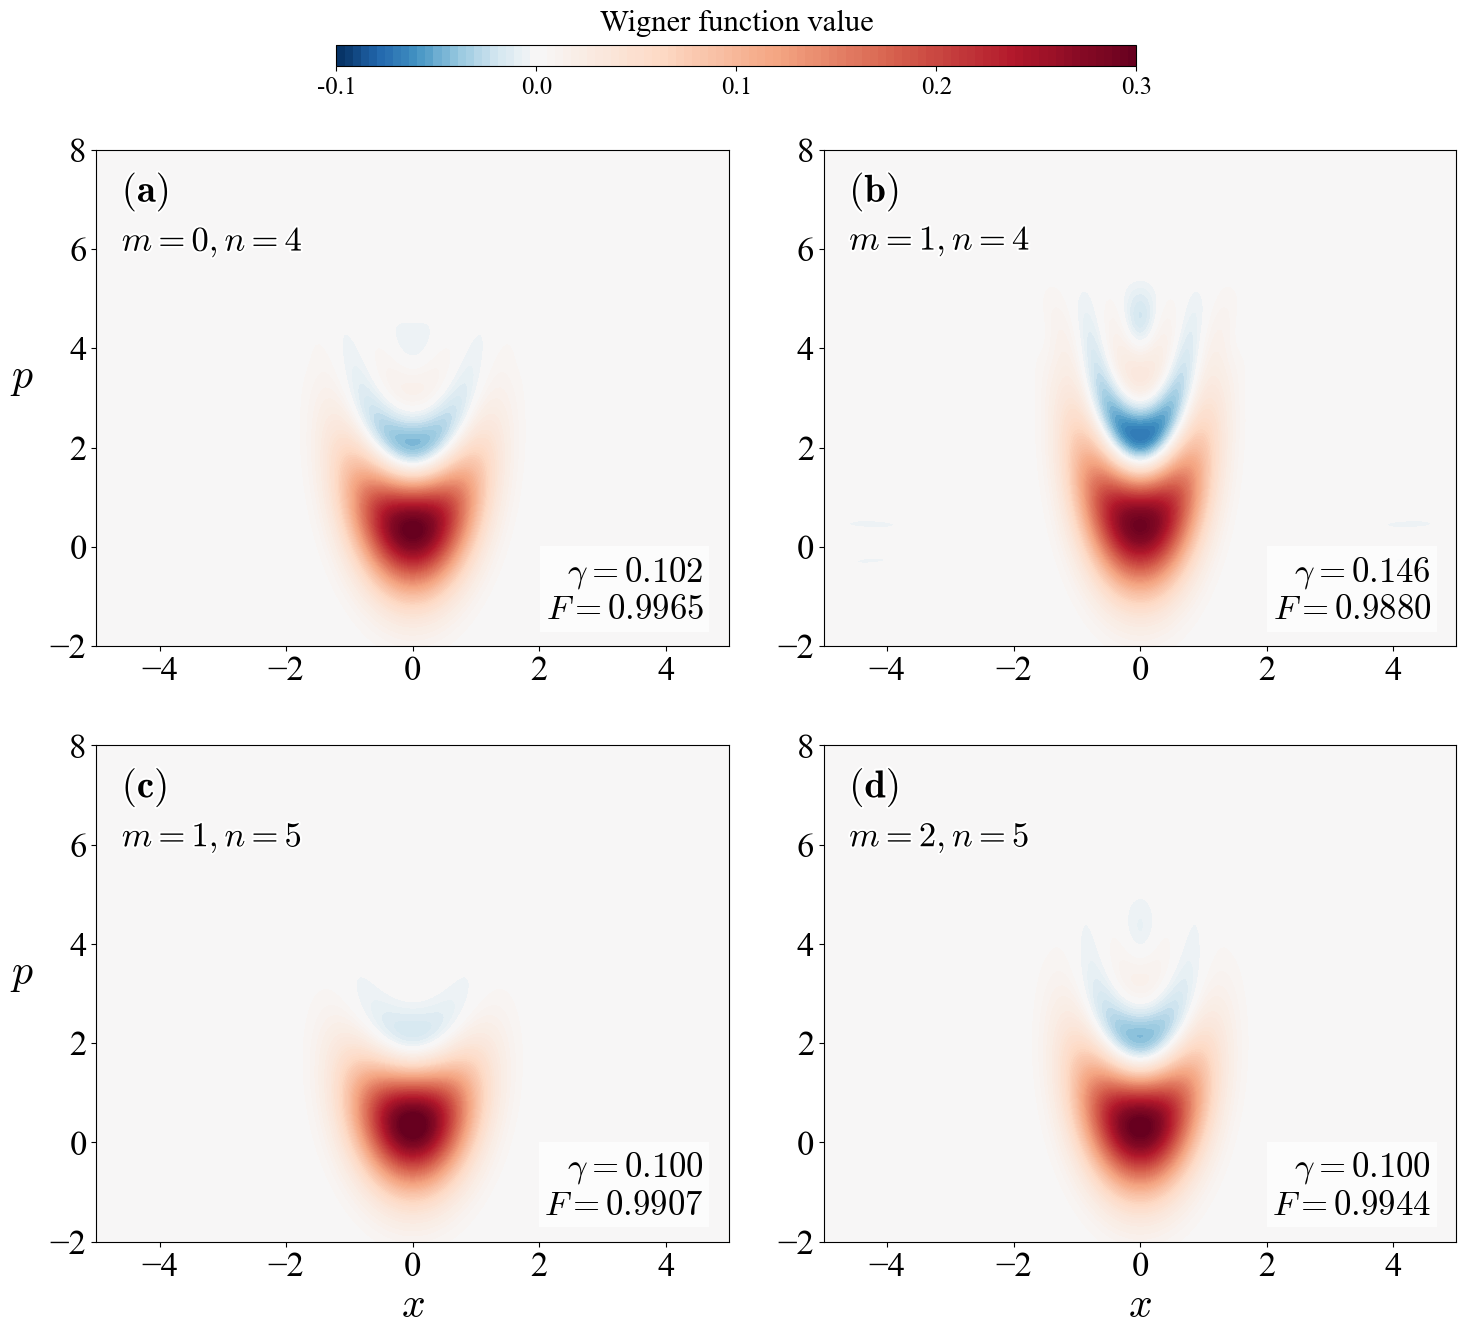

In [2]:
import numpy as np
import math
import qutip as qt
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patheffects as pe
import warnings
warnings.filterwarnings('ignore')

# ============================================================
#  全局尺寸及字号设置 (已更新为你提供的最新参数)
# ============================================================
FIG_SIZE = (16, 14)             # 画布整体物理尺寸 (宽, 高)
LABEL_SIZE = 30                 # x, p 坐标轴标签大小
TICK_SIZE = 25                  # 主图坐标轴数字刻度大小
SUBPLOT_LABEL_SIZE = 28         # (a)(b)(c)(d) 角标字体大小
CASE_LABEL_SIZE = 25            # 物理参数 (m=, n=) 文本大小
EXTRA_INFO_SIZE = 25            # 右下角额外信息 (F=, gamma=) 文本框大小
CBAR_TITLE_SIZE = 22            # 色条标题大小
CBAR_TICK_SIZE = 18             # 色条数字刻度大小

# ========== 1. 样式配置 ==========
plt.style.use('seaborn-v0_8-muted')
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman'],
    'mathtext.fontset': 'cm'
})

# ========== 2. 核心量子算符与操作 ==========
def displacement_operator(alpha, N_dim):
    """生成位移算符 D(alpha)"""
    a = qt.destroy(N_dim)
    D = (alpha * a.dag() - np.conj(alpha) * a).expm()
    return D

def squeezing_operator(r, phi, N_dim):
    """生成单模压缩算符 S(r, phi)"""
    a = qt.destroy(N_dim)
    S = ((r/2) * (np.exp(-1j*phi) * a * a - np.exp(1j*phi) * a.dag() * a.dag())).expm()
    return S

def apply_gaussian_correction(state, r_corr, beta_corr, phi=0):
    """对态施加修正操作"""
    N_dim = state.shape[0]
    D_beta = displacement_operator(beta_corr, N_dim)
    S_r = squeezing_operator(r_corr, phi, N_dim)
    
    # 直接维持纯态演化，速度极快且无舍入误差
    if state.isket:
        return S_r * D_beta * state
    else:
        return S_r * D_beta * state * D_beta.dag() * S_r.dag()

def ideal_cubic_phase_state(gamma, r_ideal, N_dim):
    """
    目标态定义为立方相位算符作用在压缩真空态上
    O = exp(i*gamma*x^3) * S(r_ideal) |0>
    """
    a = qt.destroy(N_dim)
    x = a + a.dag()
    
    S_op = qt.squeeze(N_dim, r_ideal)
    O = (1j * gamma * x**3).expm()
    
    psi = (O * S_op * qt.fock(N_dim, 0)).unit()
    return psi

def generate_single_opa_state(g_val, alpha, m, n, N_dim=50):
    """生成单个 (m,n) 的 OPA 输出态"""
    g = g_val
    G = np.sqrt(1 - 1 / (g**2))
    
    a = qt.destroy(N_dim)
    adag = a.dag()
    
    g_op_diag = [g**(-j) for j in range(N_dim)]
    g_op = qt.Qobj(np.diag(g_op_diag), dims=[[N_dim], [N_dim]])
    
    initial_state = qt.coherent(N_dim, alpha)
    
    psi_out = qt.basis(N_dim, 0) * 0.0
    for k in range(m + 1):
        if n - m + k < 0:
            continue
        num1 = (-1)**(n - m + k)
        den1 = g**(m - k + 1)
        num2 = (G**(n - m + 2 * k)) * math.sqrt(math.factorial(n) * math.factorial(m))
        den2 = math.factorial(k) * math.factorial(n - m + k) * math.factorial(m - k)
        coef = (num1 / den1) * (num2 / den2)
        term_state = coef * (adag**(n - m + k)) * g_op * (a**k) * initial_state
        psi_out += term_state
    
    return psi_out.unit()

def evaluate_fixed_parameters(fixed_params, N_dim=40):
    """根据给定的写死参数，重新计算去掉实部后的准确保真度"""
    results_dict = {}
    
    for (m, n), params in fixed_params.items():
        psi_raw = generate_single_opa_state(params['g_val'], params['alpha'], m, n, N_dim)
        psi_corrected = apply_gaussian_correction(psi_raw, params['r_corr'], params['beta_corr'])
        psi_ideal = ideal_cubic_phase_state(params['gamma'], params['r_ideal'], N_dim)
        
        fid = qt.fidelity(psi_corrected, psi_ideal)**2
        
        # 将重新计算的保真度写回字典
        params['fidelity'] = fid
        results_dict[(m, n)] = params
        
    return results_dict

# ========== 3. 控制台打印数据汇总 ==========
def print_summary_table(results_dict, selected_pairs):
    """在控制台打印精选组合的优化结果数据表格"""
    print("\n" + "=" * 115)
    print("【新参数已修正】：alpha 和 D_corr(beta) 的实部已强制抹除，以下为重新计算的纯虚数保真度")
    print("-" * 115)
    print(f"{'m':<3} | {'n':<3} | {'Fidelity':<8} | {'g':<6} | {'gamma':<6} | {'r_ideal':<8} | {'alpha':<18} | {'r_corr':<7} | {'D_corr (beta)':<18}")
    print("-" * 115)
    
    for (m, n) in selected_pairs:
        r = results_dict[(m, n)]
        alpha_str = f"0.000{np.imag(r['alpha']):+.3f}j"
        disp_str = f"0.000{np.imag(r['beta_corr']):+.3f}j"
        
        print(f"{m:<3} | {n:<3} | {r['fidelity']:.5f} | {r['g_val']:.3f}  | {r['gamma']:.4f} | {r['r_ideal']:.4f}   | {alpha_str:<18} | {r['r_corr']:.4f}  | {disp_str:<18}")
    print("=" * 115 + "\n")

# ========== 4. 色条与绘图核心逻辑 ==========
def get_asymmetric_cmap(vmin, vmax, name='RdBu_r'):
    """构建非对称 colormap"""
    cmap_base = plt.get_cmap(name)
    zero_ratio = (0.0 - vmin) / (vmax - vmin) 
    
    n_blue = int(256 * zero_ratio)
    n_red = 256 - n_blue
    
    blue_colors = cmap_base(np.linspace(0.0, 0.5, n_blue))
    red_colors = cmap_base(np.linspace(0.5, 1.0, n_red))
    
    all_colors = np.vstack((blue_colors, red_colors))
    return mcolors.LinearSegmentedColormap.from_list('shifted_cmap', all_colors)

def plot_2x2_selected_wigner(results_dict, selected_pairs, N_dim=40):
    """绘制选定的 4 张 Wigner 函数图"""
    # 🌟 使用加粗的 LaTeX 标签
    labels = [r'$\mathbf{(a)}$', r'$\mathbf{(b)}$', r'$\mathbf{(c)}$', r'$\mathbf{(d)}$']
    
    # 🌟 应用全局画布尺寸
    fig, axes = plt.subplots(2, 2, figsize=FIG_SIZE)
    axes = axes.flatten() 
    
    x_min, x_max = -5, 5
    y_min, y_max = -2, 8
    
    xvec = np.linspace(x_min, x_max, 200) 
    yvec = np.linspace(y_min, y_max, 200) 
    
    vmin, vmax = -0.1, 0.3
    levels = np.linspace(vmin, vmax, 100)
    custom_cmap = get_asymmetric_cmap(vmin, vmax, 'RdBu_r')
    text_outline = [pe.withStroke(linewidth=3, foreground='white')]

    for idx, (m, n) in enumerate(selected_pairs):
        ax = axes[idx]
        r = results_dict[(m, n)]
        
        psi_raw = generate_single_opa_state(r['g_val'], r['alpha'], m, n, N_dim)
        psi_corr = apply_gaussian_correction(psi_raw, r['r_corr'], r['beta_corr'])
            
        W = qt.wigner(psi_corr, xvec, yvec)
        W_clipped = np.clip(W, vmin, vmax)
        
        ax.contourf(xvec, yvec, W_clipped, levels=levels, cmap=custom_cmap)
        
        # 🌟 左上角角标 (a)(b)(c)(d) - 使用 SUBPLOT_LABEL_SIZE
        ax.text(0.04, 0.96, labels[idx], transform=ax.transAxes,
                fontsize=SUBPLOT_LABEL_SIZE, va='top', ha='left',
                path_effects=text_outline, color='black')
        
        # 🌟 物理参数 - 使用 CASE_LABEL_SIZE (为防止大字号重叠，Y轴稍微下调至0.85)
        ax.text(0.04, 0.85, f"$m={m}, n={n}$", transform=ax.transAxes,
                fontsize=CASE_LABEL_SIZE, va='top', ha='left',
                path_effects=text_outline, color='black')
        
        # 🌟 右下角参数框 - 使用 EXTRA_INFO_SIZE
        right_text = f"$\\gamma={r['gamma']:.3f}$\n$F={r['fidelity']:.4f}$"
        ax.text(0.96, 0.04, right_text, transform=ax.transAxes,
                fontsize=EXTRA_INFO_SIZE, va='bottom', ha='right',
                bbox=dict(facecolor='white', edgecolor='none', alpha=0.7))
        
        ax.set_xlim(x_min, x_max)
        ax.set_ylim(y_min, y_max)
        
        # 🌟 应用 TICK_SIZE
        ax.tick_params(labelsize=TICK_SIZE)
        
        # 🌟 应用 LABEL_SIZE
        if idx >= 2:
            ax.set_xlabel('$x$', fontsize=LABEL_SIZE)
        if idx % 2 == 0:
            ax.set_ylabel('$p$', fontsize=LABEL_SIZE, rotation=0, labelpad=20)
            
    # 🌟 调整主图边距，压缩 top 给色条留空间
    plt.subplots_adjust(left=0.1, right=0.95, bottom=0.1, top=0.88, wspace=0.15, hspace=0.2)
    
    # 🌟 色条移至正上方水平放置
    cbar_ax = fig.add_axes([0.25, 0.94, 0.5, 0.015])  # [x, y, width, height]
    cbar_ticks = [-0.1, 0.0, 0.1, 0.2, 0.3]
    cbar = fig.colorbar(axes[0].collections[0], cax=cbar_ax, orientation='horizontal', ticks=cbar_ticks)
    
    # 🌟 应用 CBAR_TITLE_SIZE 和 CBAR_TICK_SIZE，并将标题移至上方
    cbar.set_label('Wigner function value', fontsize=CBAR_TITLE_SIZE, labelpad=10)
    cbar.ax.xaxis.set_label_position('top')
    cbar.ax.set_xticklabels([f"{t:.1f}" for t in cbar_ticks], fontsize=CBAR_TICK_SIZE)
    
    plt.show()

# =====================================================================
# 主程序
# =====================================================================
if __name__ == "__main__":
    
    # 替换为新图片中的四组非对称/更高阶组合
    selected_pairs = [(0, 4), (1, 4), (1, 5), (2, 5)]
    N_DIM_PLOT = 40  
    
    # 提取新图片中的参数，并将 alpha 和 beta_corr 的实部全部强制设为 0.0
    image_params = {
        (0, 4): {'g_val': 1.464, 'gamma': 0.1025, 'r_ideal': -0.0001, 'alpha': 0.0 - 2.145j, 'r_corr': 0.5206, 'beta_corr': 0.0 + 2.963j},
        (1, 4): {'g_val': 1.154, 'gamma': 0.1462, 'r_ideal': -0.0135, 'alpha': 0.0 - 1.448j, 'r_corr': 0.5890, 'beta_corr': 0.0 + 2.493j},
        (1, 5): {'g_val': 1.065, 'gamma': 0.1000, 'r_ideal': -0.0000, 'alpha': 0.0 - 2.260j, 'r_corr': 0.4693, 'beta_corr': 0.0 + 3.401j},
        (2, 5): {'g_val': 1.047, 'gamma': 0.1000, 'r_ideal': -0.0000, 'alpha': 0.0 - 1.614j, 'r_corr': 0.5040, 'beta_corr': 0.0 + 2.703j},
    }
    
    print("=" * 80)
    print("正在加载新组合 (0,4), (1,4), (1,5), (2,5) 参数...")
    print("准备重计算并绘图，请稍候...")
    print("=" * 80)
    
    # 重新计算去掉实部之后的保真度
    final_results = evaluate_fixed_parameters(image_params, N_dim=N_DIM_PLOT)
    
    # 打印表格
    print_summary_table(final_results, selected_pairs)
    
    # 绘图
    plot_2x2_selected_wigner(final_results, selected_pairs, N_dim=N_DIM_PLOT)